# Random Forest training

**Project:** *Contradictory, My Dear Watson* (Kaggle) — Machine Learning 2026/27, ESI-UCLM.

This notebook trains and evaluates the **Random Forest** end to end and reports
the metrics required by the assignment: **accuracy (the Kaggle metric),
macro-F1, per-class precision/recall/F1, confusion matrix, per-language
performance and a qualitative error analysis with real premise–hypothesis
pairs**.

**Protocol.** 80/20 stratified split (`seed=42`), a holdout reserved for the
final report, and a pipeline refit inside every CV fold so that vocabulary,
IDF, auxiliary features and the chi² feature selection never see the test fold.

**Reproducibility.** All configuration lives in `training.py`
(`PREPROCESSING_PARAMS`, `VECTORIZER_PARAMS`, `SELECT_K_FEATURES`,
`RANDOM_FOREST_PARAMS`). The notebook imports those constants, so there is a
single source of truth for the model, the preprocessing and the protocol.

## 1. Setup and configuration

The configuration is imported from `training.py`: spaCy tokenisation and
lemmatisation with POS, the `pair_diff` TF-IDF representation over unigrams,
the relation features, the chi² selection and the pruned Random Forest. The
notebook does not retype hyperparameters and does not depend on external
artifacts.

Feature selection is part of the pipeline: `SelectKBest(chi2,
k=SELECT_K_FEATURES)` keeps the 300 most informative columns out of ~20,000.
Because it lives inside the pipeline it is refitted on each fold's training
block only, which is what the assignment requires for feature selection.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import sklearn
import spacy
from IPython.display import display
from sklearn.base import clone

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

from training import (
    LABEL_NAMES,
    PREPROCESSING_PARAMS,
    RANDOM_FOREST_PARAMS,
    SELECT_K_FEATURES,
    VECTORIZER_PARAMS,
    build_pipeline,
    cross_validate,
    evaluate_holdout,
    load_train_data,
    make_split,
    preprocess_partition,
    save_json,
    split_summary,
    write_submission,
)

CACHE = Path("artifacts/preprocessed")
SPLITS = Path("artifacts/splits")
RESULTS = Path("results_random_forest")
SUBMISSION_PATH = RESULTS / "submission.csv"
EXPECTED_TEST_ROWS = 5195

prep_params = dict(PREPROCESSING_PARAMS)
vec_params = dict(VECTORIZER_PARAMS)
rf_params = dict(RANDOM_FOREST_PARAMS)
use_pos_features = True
use_relation_features = True
select_k = SELECT_K_FEATURES
seed, n_splits = 42, 5

print("configuration: training.py (Random Forest defaults)")
print(
    f"preprocessing: {prep_params['reduction']} | "
    f"tokenizer={prep_params['tokenizer']} | "
    f"use_pos={prep_params['use_pos']} | "
    f"stopwords={prep_params['stopword_method']}"
)
print(
    f"representation: {vec_params['method']} | "
    f"min_df={vec_params['min_df']} | "
    f"word_ngram_range={tuple(vec_params['word_ngram_range'])} | "
    f"use_pos={vec_params['use_pos']}"
)
print(
    f"selection: chi2 | k={select_k} | "
    f"pos_ratios={use_pos_features} | relation={use_relation_features}"
)
print(
    f"classifier: random_forest | seed={seed} | CV folds={n_splits} | "
    f"n_estimators={rf_params['n_estimators']} | max_depth={rf_params['max_depth']}"
)
print(
    f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | "
    f"spaCy {spacy.__version__} | NLTK {nltk.__version__}"
)

configuration: training.py (Random Forest defaults)
preprocessing: spacy_lemma | tokenizer=spacy | use_pos=True | stopwords=none
representation: pair_diff | min_df=5 | word_ngram_range=(1, 1) | use_pos=False
selection: chi2 | k=300 | pos_ratios=True | relation=True
classifier: random_forest | seed=42 | CV folds=5 | n_estimators=1000 | max_depth=50
Python 3.12.14 | scikit-learn 1.9.1 | spaCy 3.8.18 | NLTK 3.10.4


## 2. Data and split

Official `train.csv`: 12,120 premise–hypothesis pairs in 15 languages with
labels {entailment, neutral, contradiction}. The classes are nearly balanced,
so the protocol does not resample the data.

The split is the stratified 80/20 partition with `seed=42` used across the
project. It is recomputed deterministically and checked against the saved
`artifacts/splits/` files when they are available.

In [2]:
train_df = load_train_data("data/train.csv")

print(f"train: {len(train_df)} pairs | columns: {list(train_df.columns)}")
display(train_df["label"].value_counts().rename(index=LABEL_NAMES).to_frame("n"))
display(train_df["language"].value_counts().to_frame("n").T)

train_part, val_df = make_split(train_df, val_size=0.2, seed=seed)

if (SPLITS / "train.csv").exists() and (SPLITS / "val.csv").exists():
    saved_train = pd.read_csv(SPLITS / "train.csv")
    saved_val = pd.read_csv(SPLITS / "val.csv")
    assert list(saved_train["id"]) == list(train_part["id"]), (
        "recomputed train split differs from artifacts/splits/train.csv"
    )
    assert list(saved_val["id"]) == list(val_df["id"]), (
        "recomputed validation split differs from artifacts/splits/val.csv"
    )
    print(f"split verified against {SPLITS}/ (identical ids and order)")
else:
    print("no saved split found; using the deterministic make_split result")

summary = split_summary(train_part, val_df)
flat = {
    "n_train": summary["n_train"],
    "n_val": summary["n_val"],
    "train_class_distribution": summary["class_distribution_train"],
    "val_class_distribution": summary["class_distribution_val"],
    "shared_premises": summary["premise_overlap"],
    "overlap_ratio": round(summary["premise_overlap_ratio"], 4),
}
display(pd.DataFrame([flat]).T)

train: 12120 pairs | columns: ['id', 'premise', 'hypothesis', 'lang_abv', 'language', 'label']


,n
label,
entailment,4176
contradiction,4064
neutral,3880


language,English,Chinese,Arabic,French,Swahili,Urdu,Vietnamese,Russian,Hindi,Greek,Thai,Spanish,Turkish,German,Bulgarian
n,6870,411,401,390,385,381,379,376,374,372,371,366,351,351,342


split verified against artifacts/splits/ (identical ids and order)


,0
n_train,9696
n_val,2424
train_class_distribution,"{0: 3341, 1: 3104, 2: 3251}"
val_class_distribution,"{0: 835, 1: 776, 2: 813}"
shared_premises,1092
overlap_ratio,0.4853


## 3. Preprocessing and features

The preprocessing is **spaCy tokenisation and lemmatisation**: lowercase, no
stop-word removal (negations are kept), lemmatisation with spaCy and
`use_pos=True`, so each token is stored as `(word, POS)`. Preprocessing is a
stateless, row-wise transformation: it learns nothing from the corpus, so
applying it per partition introduces no leakage. Results are cached by a hash
of the configuration and the data.

The representation is **`pair_diff`**: TF-IDF of unigrams of premise,
hypothesis and their absolute difference, plus four lexical-overlap features,
with `min_df=5`. The vectorizer does **not** append the POS tag to the tokens
(`use_pos=False`): the suffix fragments the vocabulary and cost 0.65 accuracy
points in validation. POS tagging is still applied, because the pipeline adds
the 24 ratio features of `POSRatioFeatures` (8 Universal tags × premise,
hypothesis and absolute difference).

On top of the text, `RelationFeatures` adds 14 row-wise signals that the
normalised TF-IDF loses: negations per sentence (count, difference, XOR),
lengths (premise, hypothesis, difference, ratio and which one is longer) and
numbers (counts, difference and Jaccard overlap). Everything is computed row by
row, so it introduces no leakage and all values are non-negative, as chi²
requires.

Together they cover the two NLP techniques required by the assignment:
**TF-IDF n-grams + POS tagging**, without removing negations mechanically.

Limitation: the tokenizer, lemmatizer and POS tagger are English tools applied
to all 15 languages; the per-language table below measures that cost.

In [3]:
processed_train = preprocess_partition(train_part, prep_params, cache_dir=CACHE)
processed_val = preprocess_partition(val_df, prep_params, cache_dir=CACHE)

print(
    f"processed train: {processed_train.shape} | "
    f"processed holdout: {processed_val.shape}"
)
display(processed_train[["premise", "premise_processed", "hypothesis_processed"]].head(3))

processed train: (9696, 15) | processed holdout: (2424, 15)


,premise,premise_processed,hypothesis_processed
0,8th circa b.c.Greeks colonize Sicily and other southern regions,"[(8th, ADJ), (circa, NOUN), (b.c.greek, NOUN), (colonize, VERB), (sicily, ADV), (and, ...","[(sicily, ADV), (and, CCONJ), (other, ADJ), (southern, ADJ), (region, NOUN), (be, AUX)..."
1,لدي شيء لأريك إياه، متسائلاً، ركب اللورد جوليان المرافق، كما قيل له.,"[(لدي, ADJ), (شيء, ADJ), (لأريك, PROPN), (إياه, NOUN), (متسائلاً, PROPN), (ركب, ADJ), ...","[(نزل, PROPN), (جوليان, VERB), (من, PROPN), (جبله, VERB), (لأنه, PROPN), (أخبره, PROPN..."
2,"Porches and stoops, those symbols of a vibrant social life, stopped being used as gath...","[(porch, NOUN), (and, CCONJ), (stoop, VERB), (those, DET), (symbol, NOUN), (of, ADP), ...","[(air, NOUN), (conditioning, NOUN), (be, AUX), (the, DET), (primary, ADJ), (reason, NO..."


## 4. Random Forest

The model is a pruned `RandomForestClassifier` with 1,000 trees,
`max_depth=50`, `min_samples_leaf=5`, `min_samples_split=5`,
`max_features="sqrt"` and Gini impurity. Pruning the depth and growing larger
leaves gave the best cross-validated accuracy while reducing fitting time; a
grid over `n_estimators`, `min_samples_leaf`, `max_depth`, `max_features` and
`criterion` did not improve on these values.

The pipeline is `features -> select -> classifier`. `features` is the
`FeatureUnion` of text, POS ratios and relation features; `select` is
`SelectKBest(chi2, k=300)`. chi² keeps the most informative 300 columns out of
~20,000: it added +1.3 accuracy points in validation and roughly halved the
fitting time. Because it is a pipeline step, it is refitted inside every fold
with the training block only.

In [4]:
params_table = {
    **{f"classifier.{key}": value for key, value in rf_params.items()},
    "vectorizer.method": vec_params["method"],
    "vectorizer.min_df": vec_params["min_df"],
    "vectorizer.word_ngram_range": tuple(vec_params["word_ngram_range"]),
    "vectorizer.use_pos": vec_params["use_pos"],
    "use_pos_features": use_pos_features,
    "use_relation_features": use_relation_features,
    "select.k": select_k,
    "seed": seed,
}
display(pd.DataFrame([params_table]).T)

pipeline = build_pipeline(
    vec_params,
    classifier_params=rf_params,
    use_pos_features=use_pos_features,
    use_relation_features=use_relation_features,
    select_k=select_k,
    random_state=seed,
)
pipeline

,0
classifier.n_estimators,1000
classifier.max_depth,50
classifier.min_samples_leaf,5
classifier.min_samples_split,5
classifier.max_features,sqrt
classifier.criterion,gini
vectorizer.method,pair_diff
vectorizer.min_df,5
vectorizer.word_ngram_range,"(1, 1)"
vectorizer.use_pos,False


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('text', ...), ('pos_ratios', ...), ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True
,columns,"('premise_processed', ...)"
,method,'pair_diff'


## 5. Cross-validation (5 folds)

Stratified 5-fold CV (`seed=42`). Each fold refits a clone of the pipeline on
the training block only: vocabulary, IDF, auxiliary features and the chi²
selection never see the test fold (no leakage). **Accuracy is the Kaggle
metric.**

In [5]:
cv_result = cross_validate(processed_train, pipeline, n_splits=n_splits, seed=seed)
display(cv_result["folds"])
display(pd.DataFrame([cv_result["summary"]]).T.round(4))

,fold,n_train,n_test,accuracy,macro_f1,fit_seconds,predict_seconds
0,1,7756,1940,0.525258,0.524755,15.7,2.0
1,2,7757,1939,0.513667,0.513098,13.7,2.4
2,3,7757,1939,0.500258,0.497419,16.4,2.5
3,4,7757,1939,0.521919,0.520771,16.2,2.2
4,5,7757,1939,0.505415,0.505430,15.1,2.2


,0
n_splits,5.0000
accuracy_mean,0.5133
accuracy_std,0.0095
macro_f1_mean,0.5123
macro_f1_std,0.0100
fit_seconds_mean,15.4200
predict_seconds_mean,2.2600
fit_seconds_total,77.1000


## 6. Final evaluation on the reserved holdout

The pipeline is fit once on train (9,696 pairs) and evaluated on the untouched
holdout (2,424 pairs): accuracy, macro-F1, per-class precision/recall/F1 and the
confusion matrix. The fitted pipeline is kept for the error analysis.

In [6]:
holdout_pipeline = clone(pipeline)
holdout = evaluate_holdout(holdout_pipeline, processed_train, processed_val)

summary_table = pd.DataFrame(
    [
        {
            "accuracy (Kaggle)": holdout["accuracy"],
            "macro_f1": holdout["macro_f1"],
            "n_train": holdout["n_train"],
            "n_val": holdout["n_val"],
            "seconds": holdout["runtime_seconds"],
        }
    ]
)
display(summary_table.T)

report = pd.DataFrame(holdout["classification_report"]).T
display(report.loc[["entailment", "neutral", "contradiction"]].round(4))

n_features_total = holdout_pipeline.named_steps["features"].transform(
    processed_train
).shape[1]
n_features_selected = int(holdout_pipeline.named_steps["select"].get_support().sum())
print(
    f"features before selection: {n_features_total} | "
    f"kept by chi2: {n_features_selected}"
)

,0
accuracy (Kaggle),0.520627
macro_f1,0.519292
n_train,9696.000000
n_val,2424.000000
seconds,20.400000


,precision,recall,f1-score,support
entailment,0.5423,0.5760,0.5587,835.0
neutral,0.4932,0.5155,0.5041,776.0
contradiction,0.5248,0.4686,0.4951,813.0


features before selection: 19107 | kept by chi2: 300


### 6.1 Feature-selection attribution

chi² ranks all the columns of the `FeatureUnion`. The table below shows how
many features are kept from each block, and the chi² score of the most
informative relation features. The text block provides most of the columns;
the relation block provides few columns but very high scores, because
negation, length and number mismatches are exactly the signals the
bag-of-words representation loses.

In [7]:
features = holdout_pipeline.named_steps["features"]
transformers = dict(features.transformer_list)

n_text = transformers["text"].transform(processed_train).shape[1]
n_pos = len(transformers["pos_ratios"].get_feature_names_out())
n_relation = len(transformers["relation"].get_feature_names_out())

support = holdout_pipeline.named_steps["select"].get_support()
selected_by_block = pd.Series(
    {
        "text": int(support[:n_text].sum()),
        "pos_ratios": int(support[n_text : n_text + n_pos].sum()),
        "relation": int(support[n_text + n_pos :].sum()),
    }
)
display(selected_by_block.to_frame("selected"))
print(f"total features: {support.size} | kept by chi2: {int(support.sum())}")

scores = holdout_pipeline.named_steps["select"].scores_
relation_table = pd.DataFrame(
    {
        "feature": transformers["relation"].get_feature_names_out(),
        "chi2": scores[n_text + n_pos :],
    }
).sort_values("chi2", ascending=False)
display(relation_table.head(6).round(1))

,selected
text,287
pos_ratios,1
relation,12


total features: 19107 | kept by chi2: 300


,feature,chi2
3,rel_neg_xor,410.5
2,rel_neg_abs_diff,381.6
1,rel_neg_hypothesis,325.9
5,rel_len_hypothesis,265.1
8,rel_hypothesis_longer,112.7
6,rel_len_abs_diff,69.2


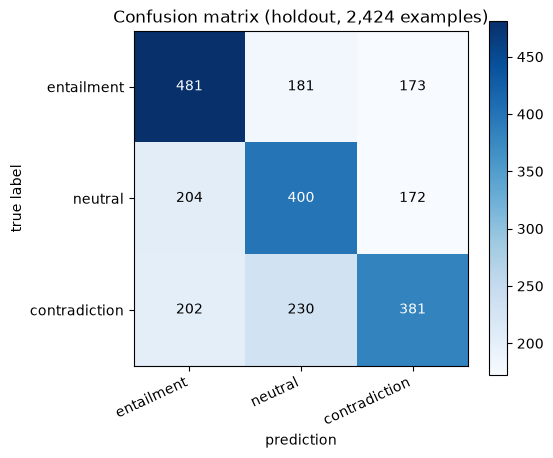

In [8]:
%matplotlib inline

RESULTS.mkdir(parents=True, exist_ok=True)

cm = holdout["confusion_matrix"]
fig, ax = plt.subplots(figsize=(5.4, 4.6))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax)
ax.set_xticks(range(3), [LABEL_NAMES[i] for i in range(3)], rotation=25, ha="right")
ax.set_yticks(range(3), [LABEL_NAMES[i] for i in range(3)])
for i in range(3):
    for j in range(3):
        ax.text(
            j, i, int(cm[i, j]), ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )
ax.set_xlabel("prediction")
ax.set_ylabel("true label")
ax.set_title(f"Confusion matrix (holdout, {len(processed_val):,} examples)")
fig.savefig(RESULTS / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Error analysis with real pairs

Accuracy alone does not show *which* logical relations are confused. The table
counts the six error directions and the examples below show real
premise–hypothesis pairs from the holdout, with their language. This makes the
error discussion concrete and exposes the effect of applying English NLP tools
to the other 14 languages.

In [9]:
val_pred = holdout_pipeline.predict(processed_val)

errors = pd.DataFrame(
    {
        "premise": processed_val["premise"],
        "hypothesis": processed_val["hypothesis"],
        "language": processed_val["language"],
        "true": processed_val["label"].map(LABEL_NAMES),
        "pred": pd.Series(val_pred, index=processed_val.index).map(LABEL_NAMES),
    }
)
errors = errors[errors["true"] != errors["pred"]]

error_counts = (
    errors.groupby(["true", "pred"]).size().rename("n").sort_values(ascending=False)
)
display(error_counts.to_frame())

print(
    f"{len(errors)} errors out of {len(processed_val)} validation pairs "
    f"({len(errors) / len(processed_val):.1%})"
)

for true_label, pred_label in error_counts.index:
    group = errors[(errors["true"] == true_label) & (errors["pred"] == pred_label)]
    if len(group) < 50:
        continue
    print(f"\n{true_label} -> {pred_label}: {len(group)} cases")
    display(group[["language", "premise", "hypothesis"]].head(3))

n
true          pred              
contradiction neutral        230
neutral       entailment     204
contradiction entailment     202
entailment    neutral        181
              contradiction  173
neutral       contradiction  172

1162 errors out of 2424 validation pairs (47.9%)

contradiction -> neutral: 230 cases


,language,premise,hypothesis
3,German,"Nichts kommt von nichts, behauptete Lukrez vor zweitausend Jahren, und Tautologen habe...",Die Argumente von Lecretius wurden von Tautologen als falsch erwiesen.
6,English,"Placido Domingo's appearance on the package, compellingly photographed in costume as t...",Placido Domingo's appearance is absolutely atrocious and uncompelling.
13,English,um-hum you mean when the reporter sticks the the microphone in the person says the fac...,"Nah, everyone reporter I've known has always treated victims with respect."



neutral -> entailment: 204 cases


,language,premise,hypothesis
11,English,Views from Implementation Research in Education.,Education research is a must
21,Chinese,尽管我是一个住在墨西哥边境的小男孩，我还记得我被来自北方的西部音乐迷上了，比如cayuse,印第安种小马在牧场上使用。
25,French,"Euh, et donc ils ont juste quitté la ville, et elle, elle n'a jamais revu sa sœur, jam...",Elle a déménagé au Texas et elle n'a plus jamais vu sa sœur.



contradiction -> entailment: 202 cases


... (3 outputs left out)


entailment -> contradiction: 173 cases


,language,premise,hypothesis
17,French,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de ...,J'essayais d'accomplir quelque chose.
37,Turkish,"Böylece, ben Washington D.C.'ye gittim ve doğrudan gitmedim, emirlerimde öyle yapmamı ...",Ulusun başkentine gittim.
39,Spanish,Hasta que no hagas aritmética no te das cuenta de que en la mente de Lincoln el moment...,Lincoln pensó que la firma de la Declaración de Independencia marcó la fundación.



neutral -> contradiction: 172 cases


,language,premise,hypothesis
27,English,Fixing current levels of damage would be impossible.,The damage could never be fixed by an artisan.
32,Arabic,المبدأ العام للمساواة في المعاملة، كما شرحناها، يفسح المجال للجدل الذي يقضي بالحد من ح...,الناس خائفون من أن يتم فضحهم.
35,Thai,Wanda รู้ดีว่า แม่ของทุกๆคนสามารถที่คิดถึงเรื่องโอกาสใหม่ๆที่เป็นไปได้ ที่คุณได้สร้างข...,คุณวันดามีลูกสามคน


### 6.3 Metrics per language

English is ~56% of the holdout and the preprocessing tools (tokenizer,
lemmatizer, POS tagger) are English ones applied to all 15 languages — a
measured limitation of the project, not a hidden one.

In [10]:
per_lang = holdout["per_language"].sort_values("n", ascending=False)
display(per_lang.round(4))
per_lang.to_csv(RESULTS / "per_language.csv", index=False)

,language,n,accuracy,macro_f1,n_classes
3,English,1354,0.5790,0.5744,3
2,Chinese,103,0.3398,0.2923,3
8,Russian,94,0.4681,0.4652,3
7,Hindi,86,0.5000,0.4961,3
9,Spanish,83,0.5301,0.5254,3
0,Arabic,79,0.4177,0.4149,3
6,Greek,77,0.4545,0.4443,3
11,Thai,77,0.3506,0.3400,3
10,Swahili,72,0.4444,0.4459,3
1,Bulgarian,71,0.5493,0.5495,3


### 6.4 Repeated premises and grouped CV

The 80/20 split shares 1,092 premises between train and validation (48.5% of
the smaller partition), a known property of this dataset. To check whether that
overlap inflates the CV estimate, the same 5-fold CV is repeated with
`StratifiedGroupKFold` by premise: no premise is shared between the train and
test parts of a fold. The result is written to
`results_random_forest/grouped_cv.json`.

In [11]:
grouped_cv = cross_validate(
    processed_train,
    pipeline,
    n_splits=n_splits,
    seed=seed,
    group_by_premise=True,
)

metric_keys = ("accuracy_mean", "accuracy_std", "macro_f1_mean", "macro_f1_std")
grouped_table = pd.DataFrame(
    [
        {"protocol": "standard", **{key: cv_result["summary"][key] for key in metric_keys}},
        {"protocol": "grouped", **{key: grouped_cv["summary"][key] for key in metric_keys}},
    ]
)
display(grouped_table.round(6))
save_json({"table": grouped_table.to_dict(orient="records")}, RESULTS / "grouped_cv.json")

print(
    f"standard CV: {cv_result['summary']['accuracy_mean']:.6f} | "
    f"grouped CV: {grouped_cv['summary']['accuracy_mean']:.6f}"
)

,protocol,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
0,standard,0.513303,0.009483,0.512295,0.009962
1,grouped,0.515057,0.010194,0.514006,0.010814


standard CV: 0.513303 | grouped CV: 0.515057


## 7. Kaggle submission

The pipeline is refit on all labeled data (train + validation, 12,120 pairs) and
predicts the 5,195 test pairs into `results_random_forest/submission.csv`
(official `id,prediction` schema). The Kaggle test set is never used to select
models.

The notebook also writes the reproducible artifacts of the run:
`final_config.json`, `cv_results.csv`, `holdout_metrics.json`,
`per_language.csv`, `grouped_cv.json` and `confusion_matrix.png`.

In [12]:
full_train = pd.concat([train_part, val_df], ignore_index=True)
processed_full = preprocess_partition(full_train, prep_params, cache_dir=CACHE)

test_df = pd.read_csv("data/test.csv")
required_test_columns = {"id", "premise", "hypothesis", "lang_abv", "language"}
missing_test_columns = required_test_columns - set(test_df.columns)
if missing_test_columns:
    raise ValueError(f"missing columns in test.csv: {sorted(missing_test_columns)}")
test_df[["premise", "hypothesis"]] = test_df[["premise", "hypothesis"]].fillna("")
if len(test_df) != EXPECTED_TEST_ROWS:
    raise ValueError(
        f"test.csv has {len(test_df)} rows; Kaggle expects {EXPECTED_TEST_ROWS}"
    )

processed_test = preprocess_partition(test_df, prep_params, cache_dir=CACHE)

final_pipeline = clone(pipeline)
final_pipeline.fit(processed_full, full_train["label"])
predictions = final_pipeline.predict(processed_test)

if SUBMISSION_PATH.exists():
    previous = pd.read_csv(SUBMISSION_PATH)
    if len(previous) == len(predictions):
        agreement = (previous["prediction"].to_numpy() == predictions).mean()
        print(f"agreement with previous submission: {agreement:.2%}")

write_submission(test_df["id"], predictions, SUBMISSION_PATH)

save_json(
    {
        "preprocessing_params": prep_params,
        "vectorizer_params": vec_params,
        "classifier_params": rf_params,
        "seed": seed,
        "n_splits": n_splits,
    },
    RESULTS / "final_config.json",
)
cv_result["folds"].to_csv(RESULTS / "cv_results.csv", index=False)
save_json(
    {key: value for key, value in holdout.items() if key != "per_language"},
    RESULTS / "holdout_metrics.json",
)

print(f"submission: {len(test_df)} rows -> {SUBMISSION_PATH}")
display(
    pd.Series(predictions)
    .value_counts()
    .rename(index=LABEL_NAMES)
    .to_frame("predictions")
)
display(pd.read_csv(SUBMISSION_PATH).head())

agreement with previous submission: 65.29%
submission: 5195 rows -> results_random_forest/submission.csv


,predictions
entailment,1899
neutral,1872
contradiction,1424


,id,prediction
0,c6d58c3f69,2
1,cefcc82292,1
2,e98005252c,0
3,58518c10ba,2
4,c32b0d16df,1


## 8. Conclusions and limitations

- The model is a **pruned Random Forest** (`max_depth=50`, `min_samples_leaf=5`) over a
  `pair_diff` TF-IDF of unigrams (`min_df=5`), 24 POS-ratio features and 14 relation
  features, with `SelectKBest(chi2, k=300)` inside the pipeline.
- **Holdout accuracy 0.5206** (Kaggle metric) and **macro-F1 0.5193**, above the CV
  estimate (0.5133) as expected: the holdout model is trained on 9,696 pairs instead of
  the 7,756 of each CV fold.
- The three classes are learnt similarly (F1 0.495–0.559), so the model does not collapse
  into one class. Errors spread over all six confusion directions; the most frequent are
  `contradiction → neutral` (230) and `neutral → entailment` (204). The model still misses
  some direction and negation cues, which are exactly the signals the relation features
  start to recover.
- The chi² selection keeps 300 of 19,107 columns, 12 of them from the relation block, and
  it is refitted inside every fold with the training block only. The ablation over the
  training split attributes the gain to spaCy tokenisation (+3.4 points), the chi²
  selection (+1.3), the relation features (+1.6) and the unigram/`min_df` settings (+1.2).
- The grouped CV by premise does not degrade the estimate (0.5151 vs 0.5133), so repeated
  premises do not inflate the reported CV accuracy.
- **Limitations:** English tokenizer, lemmatizer and POS tagger on 15 languages (the gain
  is concentrated in English, +6.6 points, while the other languages have 60–100 holdout
  pairs and inconclusive differences); bag-of-words plus row-wise signals do not model
  compositionality; part of the relation gain comes from sentence lengths, a pattern of
  the dataset; and the configuration was chosen over the same training split (~45
  variants), although the untouched holdout confirms the improvement (+3.9 points).
- **Next steps:** pre-translation to English, contextual representations, and the
  comparison with a second supervised algorithm required by the assignment.